# Предсказание калорийности блюд

### **Описание задачи**
Задача состоит в создании и обучении нейросети, которая будет предсказывать калорийность блюд. Полученную модель можно интегрировать во многие fitness и health-приложения, она будет полезна тем, кто следит за своим здоровьем. 

### **Цель**
Получить DL-модель, способную оценить калорийность блюда.

### **Целевая метрика**
Модель будет считаться готовой к интеграции в продукт при точности оценки `MAE < 50` (MAE — Mean Absolute Error) на тестовой выборке. 

### **Датасет**
Датасет содержит фотографии блюд, описание ингредиентов, а также общую массу порции и калорийность.

## Этап 1. Исследовательский анализ данных

## 0. Установка библиотек и загрузка датасета

In [1]:
%pip install -q -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [2]:
import zipfile
from pathlib import Path

import gdown
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

pd.set_option("display.max_colwidth", 150)
plt.rcParams.update({
    "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False,
})
BLUE, ORANGE = "#2a78d6", "#eb6834"

In [ ]:
GDRIVE_FILE_ID = "19cIhxmvhRVpRqGHnBCbxLEfEZ51jvsTG"
ARCHIVE = Path("nutrition.zip")
DATA_DIR = Path("data")

if not (DATA_DIR / "dish.csv").exists():
    if not ARCHIVE.exists():
        gdown.download(id=GDRIVE_FILE_ID, output=str(ARCHIVE), quiet=False)
    with zipfile.ZipFile(ARCHIVE) as zf:
        zf.extractall(".")

## 1. Первый взгляд на таблицы

In [ ]:
dish = pd.read_csv(DATA_DIR / "dish.csv")
ingredients = pd.read_csv(DATA_DIR / "ingredients.csv")
print("dish.csv:", dish.shape)
print("ingredients.csv:", ingredients.shape)
dish.head()

dish.csv: (3262, 5)
ingredients.csv: (555, 2)


,dish_id,total_calories,total_mass,ingredients,split
0,dish_1561662216,300.794281,193.0,ingr_0000000508;ingr_0000000122;ingr_0000000026;ingr_0000000524;ingr_0000000094;ingr_0000000023;ingr_0000000189;ingr_0000000054;ingr_0000000029;in...,test
1,dish_1561662054,419.438782,292.0,ingr_0000000312;ingr_0000000026;ingr_0000000029;ingr_0000000122;ingr_0000000508;ingr_0000000513;ingr_0000000520;ingr_0000000525;ingr_0000000161;in...,train
2,dish_1562008979,382.936646,290.0,ingr_0000000448;ingr_0000000520;ingr_0000000462;ingr_0000000514;ingr_0000000152;ingr_0000000312;ingr_0000000291;ingr_0000000045;ingr_0000000122;in...,test
3,dish_1560455030,20.590000,103.0,ingr_0000000471;ingr_0000000031;ingr_0000000347,train
4,dish_1558372433,74.360001,143.0,ingr_0000000453,train


In [5]:
ingredients.head()

,id,ingr
0,1,cottage cheese
1,2,strawberries
2,3,garden salad
3,4,bacon
4,5,potatoes


In [6]:
dish.info()

<class 'pandas.DataFrame'>
RangeIndex: 3262 entries, 0 to 3261
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   dish_id         3262 non-null   str    
 1   total_calories  3262 non-null   float64
 2   total_mass      3262 non-null   float64
 3   ingredients     3262 non-null   str    
 4   split           3262 non-null   str    
dtypes: float64(2), str(3)
memory usage: 127.6 KB


In [7]:
dish["split"].value_counts()

split
train    2755
test      507
Name: count, dtype: int64

В датасете 3262 блюда и 555 ингредиентов, пропусков нет, типы колонок нормальные, в train - 2755 блюд, в test - 507.

## 2. Проверка качества данных

Проверяю дубликаты, наличие фотографий для каждого блюда и сами ингредиенты.

In [8]:
print("Дубликатов dish_id", dish["dish_id"].duplicated().sum())
print("Дубликатов id ингредиента", ingredients["id"].duplicated().sum())

image_ids = {p.name for p in (DATA_DIR / "images").iterdir()}
print("Блюд без фото", (~dish["dish_id"].isin(image_ids)).sum())
print("Папок с фото, которых нет в dish.csv", len(image_ids - set(dish["dish_id"])))

Дубликатов dish_id 0
Дубликатов id ингредиента 0
Блюд без фото 0
Папок с фото, которых нет в dish.csv 228


In [9]:
ingredients[ingredients["ingr"].duplicated(keep=False)]

,id,ingr
230,231,deprecated
452,453,deprecated
457,458,deprecated
469,470,deprecated


In [10]:
dish_ingr_ids = dish["ingredients"].str.split(";").apply(lambda ids: {int(i.replace("ingr_", "")) for i in ids})
deprecated = set(ingredients.loc[ingredients["ingr"] == "deprecated", "id"])

print("Блюд, где встречается deprecated", dish_ingr_ids.apply(lambda ids: bool(ids & deprecated)).sum())
print("Блюд, где все ингредиенты deprecated", dish_ingr_ids.apply(lambda ids: ids <= deprecated).sum())

used = set().union(*dish_ingr_ids)
print("Уникальных ингредиентов в блюдах", len(used), "из", len(ingredients))
print("Все ID есть в ingredients.csv", used <= set(ingredients["id"]))

train_ids = set().union(*dish_ingr_ids[dish["split"] == "train"])
test_ids = set().union(*dish_ingr_ids[dish["split"] == "test"])
print("Ингредиентов из test, которых нет в train", len(test_ids - train_ids))

Блюд, где встречается deprecated 31
Блюд, где все ингредиенты deprecated 16
Уникальных ингредиентов в блюдах 200 из 555
Все ID есть в ingredients.csv True
Ингредиентов из test, которых нет в train 2


С данными в целом всё хорошо. У каждого блюда есть фото, а 228 лишних папок с фотографиями просто не используются. Все ID ингредиентов из `dish.csv` находятся в справочнике.

Есть одна странность. В справочнике 4 ингредиента называются `deprecated`, видимо это старые записи, у которых стёрли название. Они встречаются в 31 блюде, а 16 блюд целиком из них состоят. Для текстовой части модели такое слово бесполезно, поэтому при объединении таблиц я его выкидываю. У этих 16 блюд текст будет пустым, и модель будет опираться на фото и массу.

Ещё видно, что в блюдах используется только 200 ингредиентов из 555, а в test почти нет ингредиентов, которых не было бы в train (всего 2). Значит, текстовая часть на тесте не столкнётся с незнакомыми продуктами.

## 3. Целевая переменная и масса порции

In [11]:
dish[["total_calories", "total_mass"]].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).round(1)

,total_calories,total_mass
count,3262.0,3262.0
mean,255.0,215.0
std,219.6,161.5
min,0.0,1.0
1%,6.4,14.0
25%,80.1,92.0
50%,209.1,177.0
75%,375.1,305.0
99%,918.5,702.3
max,3943.3,3051.0


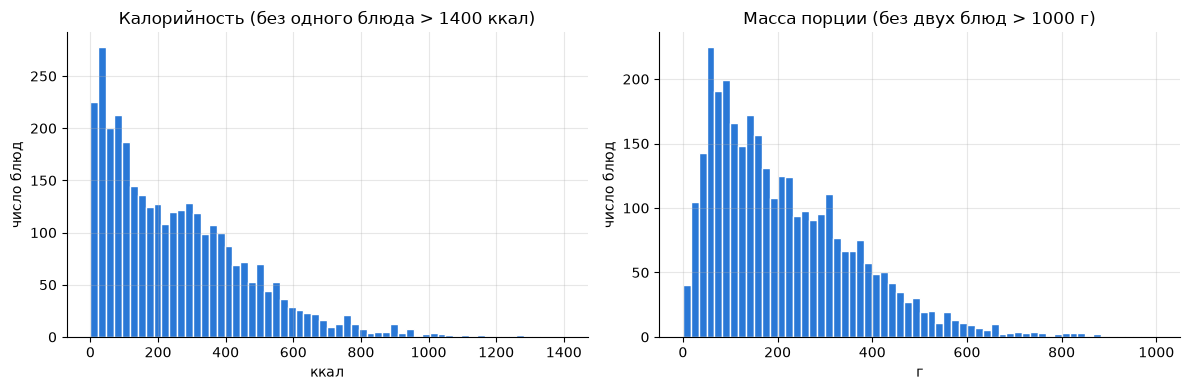

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(dish["total_calories"], bins=60, range=(0, 1400), color=BLUE, edgecolor="white")
axes[0].set(title="Калорийность (без одного блюда > 1400 ккал)", xlabel="ккал", ylabel="число блюд")
axes[1].hist(dish["total_mass"], bins=60, range=(0, 1000), color=BLUE, edgecolor="white")
axes[1].set(title="Масса порции (без двух блюд > 1000 г)", xlabel="г", ylabel="число блюд")
plt.tight_layout()
plt.show()

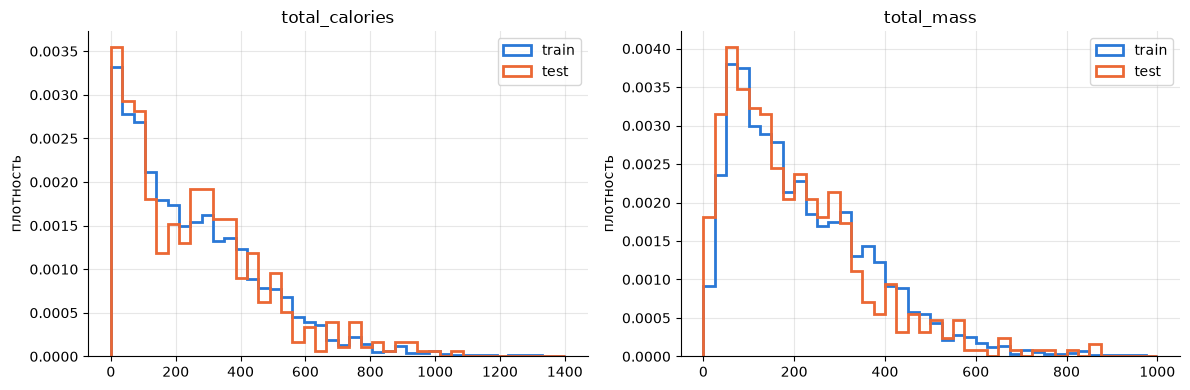

total_calories        total_mass       
                mean median       mean median
split                                        
test           255.5  226.0      198.5  161.0
train          254.9  208.1      218.0  179.0

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col, rng in [(axes[0], "total_calories", (0, 1400)), (axes[1], "total_mass", (0, 1000))]:
    for split, color in [("train", BLUE), ("test", ORANGE)]:
        ax.hist(dish.loc[dish["split"] == split, col], bins=40, range=rng, density=True,
                histtype="step", linewidth=2, color=color, label=split)
    ax.set(title=col, ylabel="плотность")
    ax.legend()
plt.tight_layout()
plt.show()

dish.groupby("split")[["total_calories", "total_mass"]].agg(["mean", "median"]).round(1)

In [14]:
dish.sort_values("total_calories", ascending=False).head(5)[["dish_id", "total_calories", "total_mass", "split"]]

,dish_id,total_calories,total_mass,split
1518,dish_1560974769,3943.325195,3051.0,train
124,dish_1565033265,1324.084961,625.0,train
2753,dish_1562603895,1268.157349,517.0,train
1125,dish_1564170010,1264.548340,831.0,train
1951,dish_1563476577,1238.033691,857.0,train


In [15]:
dish[dish["total_calories"] < 5][["dish_id", "total_calories", "total_mass", "ingredients"]].head(10)

,dish_id,total_calories,total_mass,ingredients
26,dish_1558549773,2.30,10.0,ingr_0000000036
195,dish_1558461431,1.15,5.0,ingr_0000000036
263,dish_1557861216,0.00,1.0,ingr_0000000423
505,dish_1558629644,4.20,15.0,ingr_0000000029
906,dish_1558462036,2.99,13.0,ingr_0000000036
1086,dish_1562959295,3.04,19.0,ingr_0000000073
1209,dish_1558548958,2.30,10.0,ingr_0000000036
1311,dish_1556575124,4.48,28.0,ingr_0000000034
1351,dish_1558458438,3.22,14.0,ingr_0000000036
1421,dish_1558641211,3.28,8.0,ingr_0000000045


Распределение калорийности сильно скошено вправо. Медиана около 209 ккал, среднее 255, у 99% блюд меньше 920 ккал. С массой картина похожая, медиана 177 г. Train и test распределены почти одинаково, так что тест репрезентативный.

Справа выделяется одно блюдо `dish_1560974769` на 3943 ккал и 3051 г. Это в три раза больше следующего по калорийности блюда, ниже я посмотрю на его фото. Слева, наоборот, есть около 25 блюд меньше 5 ккал. Это порции в несколько граммов из одного продукта (шпинат, огурцы, зелень) и пара блюд с ингредиентом `plate only` и нулевой калорийностью, то есть по сути пустая тарелка. Такие примеры выглядят правдоподобно, их я оставлю.

## 4. Связь калорийности и массы

Корреляция Пирсона 0.76


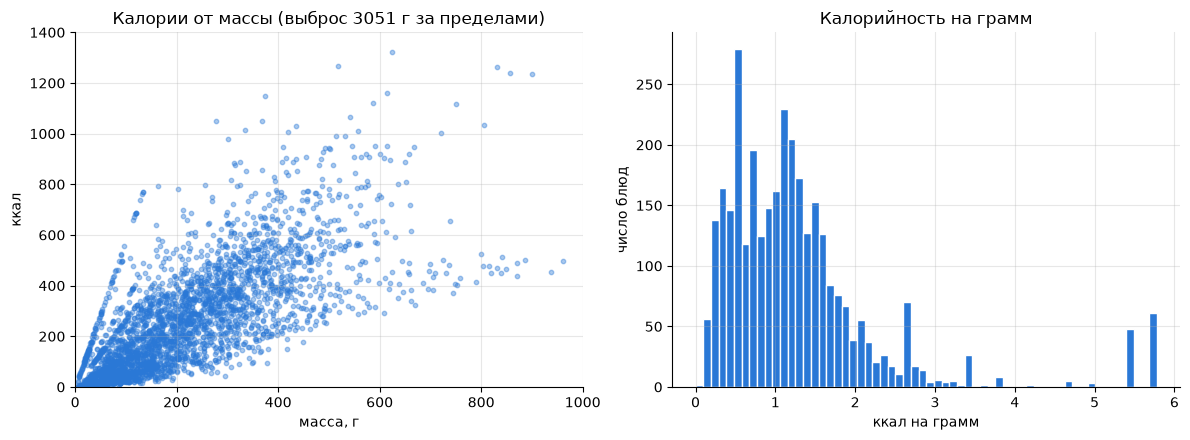

count    3262.00
mean        1.30
std         1.07
min         0.00
25%         0.60
50%         1.10
75%         1.56
max         5.78
Name: kcal_per_g, dtype: float64

In [16]:
print("Корреляция Пирсона", round(dish["total_calories"].corr(dish["total_mass"]), 3))

dish["kcal_per_g"] = dish["total_calories"] / dish["total_mass"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(dish["total_mass"], dish["total_calories"], s=10, alpha=0.4, color=BLUE)
axes[0].set(xlim=(0, 1000), ylim=(0, 1400), xlabel="масса, г", ylabel="ккал",
            title="Калории от массы (выброс 3051 г за пределами)")
axes[1].hist(dish["kcal_per_g"], bins=60, color=BLUE, edgecolor="white")
axes[1].set(xlabel="ккал на грамм", ylabel="число блюд", title="Калорийность на грамм")
plt.tight_layout()
plt.show()

dish["kcal_per_g"].describe().round(2)

Масса сильно связана с калорийностью, корреляция около 0.76. Поэтому `total_mass` обязательно надо подавать в модель как отдельный числовой признак. Предсказать вес порции по одному фото гораздо сложнее, чем взять его из таблицы.

При этом на графике видно, что при одной и той же массе калорийность может отличаться в разы. Плотность варьируется от 0 до почти 6 ккал на грамм, медиана около 1.1. Салат и кусок мяса с маслом могут весить одинаково, а различаться по калориям в несколько раз. Именно эту разницу модель и должна извлечь из фото и списка ингредиентов.

## 5. Объединение `dish.csv` и `ingredients.csv`

В колонке `ingredients` лежат технические ID вида `ingr_0000000122`, из которых модель ничего не поймёт. Заменяю их на названия из `ingredients.csv`, разделитель делаю запятой, чтобы получился обычный текст. Ингредиенты `deprecated` при этом пропускаю.

In [17]:
id2name = dict(zip(ingredients["id"], ingredients["ingr"]))


def ingredients_to_text(ingr_ids):
    names = [id2name[int(i.replace("ingr_", ""))] for i in ingr_ids.split(";")]
    return ", ".join(n for n in names if n != "deprecated")


df = dish.copy()
df["ingredients"] = df["ingredients"].apply(ingredients_to_text)

before_after = pd.DataFrame({
    "ingredients_ids": dish["ingredients"],
    "ingredients_text": df["ingredients"],
})
before_after.head(5)

,ingredients_ids,ingredients_text
0,ingr_0000000508;ingr_0000000122;ingr_0000000026;ingr_0000000524;ingr_0000000094;ingr_0000000023;ingr_0000000189;ingr_0000000054;ingr_0000000029;in...,"soy sauce, garlic, white rice, parsley, onions, brown rice, vinegar, apple, mixed greens, sugar, salt, lemon juice, olive oil, pork, bok choy, pep..."
1,ingr_0000000312;ingr_0000000026;ingr_0000000029;ingr_0000000122;ingr_0000000508;ingr_0000000513;ingr_0000000520;ingr_0000000525;ingr_0000000161;in...,"pepper, white rice, mixed greens, garlic, soy sauce, millet, lemon juice, bok choy, olive oil, onions, vinegar, green beans, pork, apple, sugar, s..."
2,ingr_0000000448;ingr_0000000520;ingr_0000000462;ingr_0000000514;ingr_0000000152;ingr_0000000312;ingr_0000000291;ingr_0000000045;ingr_0000000122;in...,"jalapenos, lemon juice, pork, wheat berry, cabbage, pepper, salt, carrot, garlic, caesar salad, olive oil, parsley, mayonnaise"
3,ingr_0000000471;ingr_0000000031;ingr_0000000347,"cherry tomatoes, cucumbers, baby carrots"
4,ingr_0000000453,


In [18]:
print("Пустой текст у", (df["ingredients"] == "").sum(), "блюд")
df[["dish_id", "total_calories", "total_mass", "ingredients", "split"]].sample(5, random_state=0)

Пустой текст у 16 блюд


,dish_id,total_calories,total_mass,ingredients,split
2464,dish_1562169840,739.663696,389.0,"sausage, olive oil, brussels sprouts, mixed greens, raspberries, salt, vinaigrette, pepper, granola, scrambled eggs, blackberries",train
1515,dish_1562702379,100.882935,227.0,"lettuce, cherry tomatoes, bell peppers, cucumbers, feta cheese, onions, olives, cauliflower, vinaigrette",train
2756,dish_1564170836,240.164917,135.0,"salmon, olive oil, arugula, brown rice, salt, pepper, thyme",train
654,dish_1563309398,655.986816,604.0,"salt, spinach (raw), lemon juice, olives, bell peppers, lettuce, garlic, chicken, cherry tomatoes, wheat berry, parsley, thyme, olive oil, shallot...",train
1998,dish_1561746970,303.636078,363.0,"garlic, salt, tatsoi, thyme, olive oil, kale, cucumbers, brown rice, arugula, lemon juice, parsley, wheat berry, pepper, salmon",train


Теперь в колонке `ingredients` осмысленный текст, например `chicken, olive oil, garlic, salt`. Такой вход уже можно подавать в предобученный текстовый энкодер. Пустой текст только у тех 16 блюд, которые целиком состояли из `deprecated`.

## 6. Ингредиенты

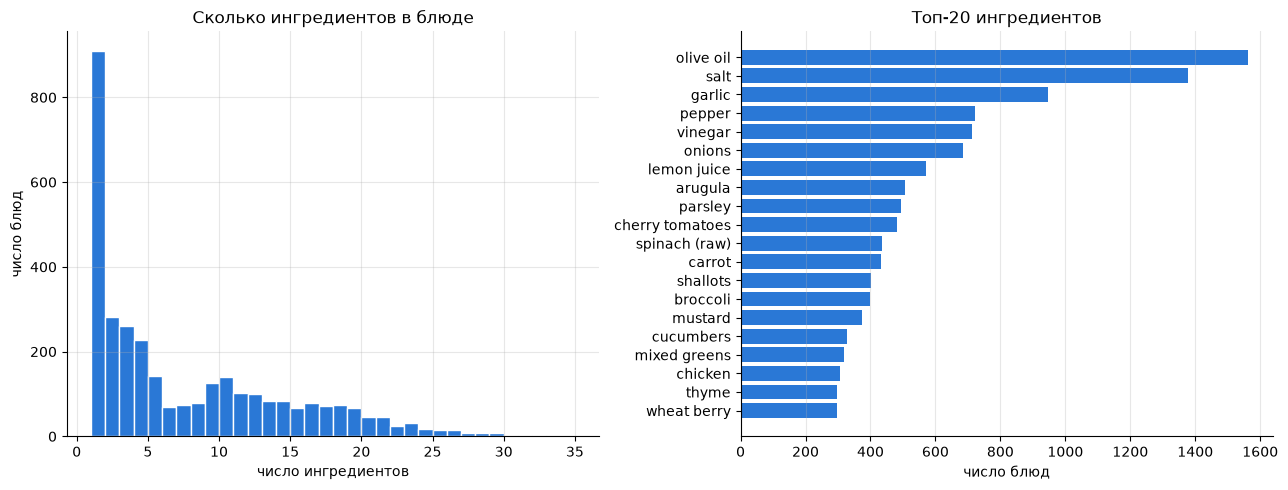

Блюд из одного ингредиента 910


In [19]:
df["n_ingr"] = dish["ingredients"].str.count(";") + 1

all_ingr = df["ingredients"].str.split(", ").explode()
top_ingr = all_ingr[all_ingr != ""].value_counts().head(20)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].hist(df["n_ingr"], bins=range(1, 36), color=BLUE, edgecolor="white")
axes[0].set(xlabel="число ингредиентов", ylabel="число блюд", title="Сколько ингредиентов в блюде")
axes[1].barh(top_ingr.index[::-1], top_ingr.values[::-1], color=BLUE)
axes[1].set(xlabel="число блюд", title="Топ-20 ингредиентов")
axes[1].grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

print("Блюд из одного ингредиента", (df["n_ingr"] == 1).sum())

In [20]:
df.groupby(pd.cut(df["n_ingr"], [0, 1, 5, 10, 40]), observed=True)["total_calories"].agg(["count", "median"]).round(1)

,count,median
n_ingr,,
"(0, 1]",910,64.9
"(1, 5]",912,203.0
"(5, 10]",489,264.1
"(10, 40]",951,360.2


В среднем в блюде около 7 ингредиентов, но разброс большой, от 1 до 34. Заметная группа блюд (910 штук, 28%) состоит из одного продукта, и они в среднем гораздо легче. Чем больше ингредиентов, тем выше медианная калорийность, так что длина списка тоже несёт информацию.

Чаще всего встречаются оливковое масло, соль, чеснок, перец и уксус. Это заправки и специи, они есть почти везде. Масло при этом очень калорийное, и его количество по фото определить трудно, это один из источников ошибок модели.

## 7. Фотографии

In [21]:
def image_path(dish_id):
    return DATA_DIR / "images" / dish_id / "rgb.png"


def load_image(dish_id):
    return Image.open(image_path(dish_id)).convert("RGB")


sizes = pd.Series([Image.open(image_path(i)).size for i in df["dish_id"]]).value_counts()
sizes

(640, 480)    3262
Name: count, dtype: int64

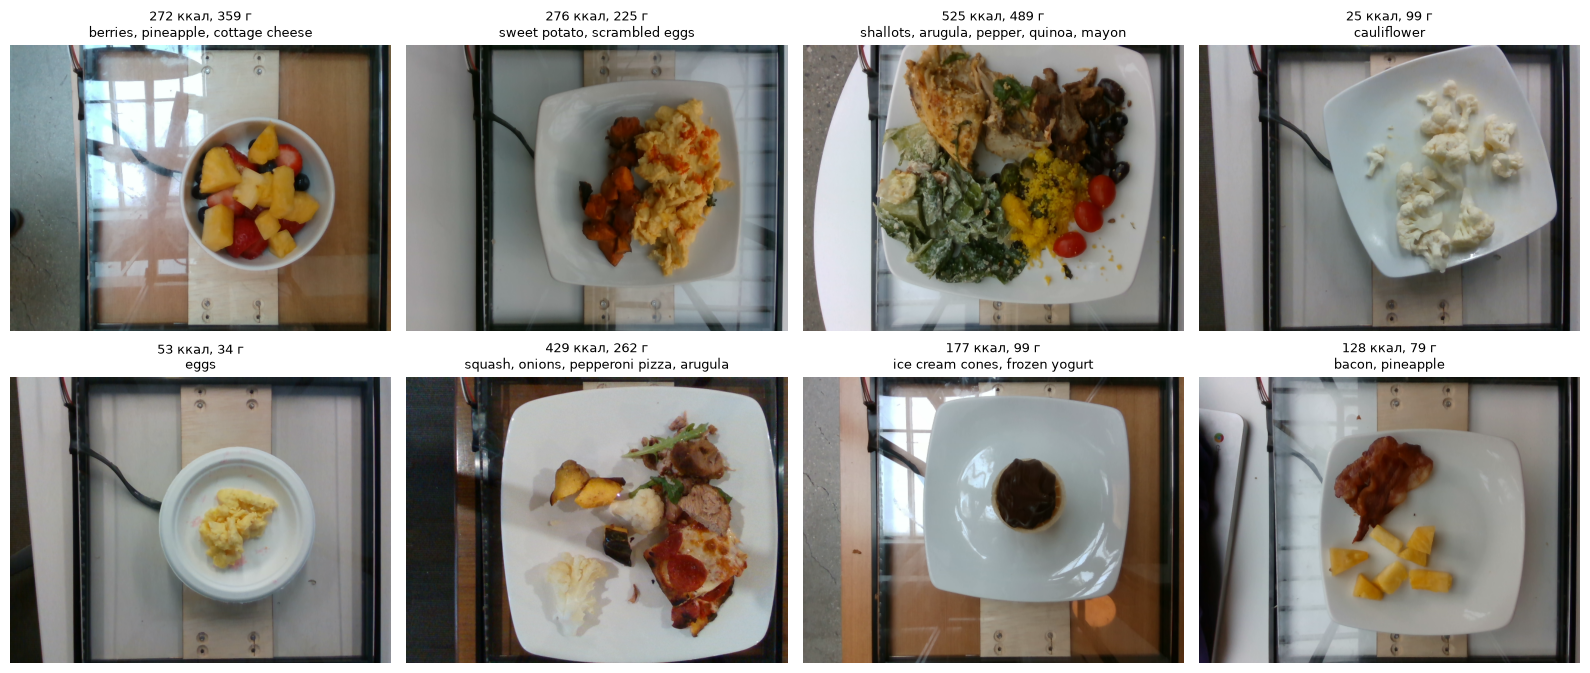

In [22]:
sample = df.sample(8, random_state=42)

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, (_, row) in zip(axes.ravel(), sample.iterrows()):
    ax.imshow(load_image(row["dish_id"]))
    ax.set_title(f"{row['total_calories']:.0f} ккал, {row['total_mass']:.0f} г\n{row['ingredients'][:40]}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

dish_id                                                                                                                                          dish_1560974769
total_calories                                                                                                                                       3943.325195
total_mass                                                                                                                                                3051.0
split                                                                                                                                                      train
ingredients       spinach (raw), tortilla chips, corn, cheese, white rice, cherry tomatoes, lime, tomatoes, chili, garlic, salt, sour cream, onions, black beans


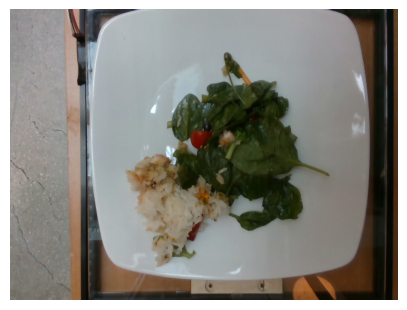

In [23]:
outlier = df.loc[df["total_calories"].idxmax()]
print(outlier[["dish_id", "total_calories", "total_mass", "split", "ingredients"]].to_string())

plt.figure(figsize=(5, 4))
plt.imshow(load_image(outlier["dish_id"]))
plt.axis("off")
plt.show()

Все фотографии одного размера 640x480 и сняты сверху одной камерой. Блюда стоят на одном и том же столе, в основном на белых тарелках и в мисках разной формы. Это удобно, потому что камера всегда на одной высоте и масштаб на всех снимках одинаковый, значит по площади еды на фото можно судить о размере порции. Фон тоже почти везде одинаковый.

Блюдо с 3943 ккал оказалось явной ошибкой разметки. На фото небольшая порция шпината с рисом на обычной тарелке, а по таблице там 3 кг еды и 14 ингредиентов вроде чипсов, сыра и фасоли. Это блюдо лежит в train, и при обучении я его уберу, иначе оно сильно исказит лосс.

## 8. Видение решения

### Как решать задачу

Задача мультимодальная, у каждого блюда есть фото, текст и число. Планирую такую модель.

- Изображение кодирую предобученной CNN или ViT из `timm` (например, EfficientNet или ResNet). Сначала заморожу почти все слои и дообучу последние блоки.
- Список ингредиентов кодирую предобученным текстовым энкодером типа BERT из `transformers` и беру эмбеддинг CLS-токена или усреднение по токенам.
- Массу порции подаю как отдельный нормированный числовой признак, так как это самый сильный признак из всех.
- Эмбеддинги склеиваю и подаю в небольшую MLP-голову, которая выдаёт калорийность.

Для валидации отрежу от train 15-20% блюд, а test использую только один раз для финальной оценки. Ещё один вариант, который хочу попробовать, это предсказывать калорийность на грамм и умножать её на массу. Тогда модели не нужно самой учиться масштабу порции.

### Обогащение и аугментация данных

Обогащение данных.
- ID ингредиентов заменены на названия (сделано выше), без этого текстовая часть бессмысленна.
- Масса используется как отдельный признак.
- `deprecated` выкидываю из текста, выброс `dish_1560974769` убираю из train.

Аугментации изображений. Фото сняты строго сверху, поэтому у блюда нет верха и низа.
- Горизонтальные и вертикальные отражения, повороты на любой угол. Это безопасно и заметно увеличивает разнообразие.
- Небольшие изменения яркости и контраста, потому что освещение на снимках немного отличается.
- Сильный `RandomResizedCrop` и сдвиг оттенка (hue) использовать не буду. Масштаб на всех фото одинаковый, и сильный зум исказит видимый размер порции, а ещё может обрезать часть еды. Цвет же помогает отличить, например, масло от воды или курицу от тофу.

Аугментация текста. Порядок ингредиентов в списке ничего не значит, поэтому буду случайно перемешивать его при обучении. Удалять ингредиенты из списка нельзя, так как калорийность блюда от этого изменится, а метка останется прежней.

### Метрики

Основная метрика это MAE, так как именно она стоит в критерии готовности модели. В качестве лосса возьму L1 или Huber (SmoothL1). Они согласованы с MAE и меньше реагируют на оставшиеся выбросы, чем MSE. Дополнительно буду смотреть RMSE, чтобы видеть, нет ли у модели редких, но очень больших ошибок. Лучшую эпоху выбираю по MAE на валидации.

Чтобы понять, насколько планка в 50 ккал сложная, посчитаю MAE двух совсем простых предсказаний на test.

In [24]:
train, test = df[df["split"] == "train"], df[df["split"] == "test"]

median_pred = train["total_calories"].median()
kcal_per_g = train["total_calories"].sum() / train["total_mass"].sum()

print(f"MAE медианы train {np.abs(test['total_calories'] - median_pred).mean():.1f}")
print(f"MAE прогноза 'средние ккал на грамм * масса' {np.abs(test['total_calories'] - kcal_per_g * test['total_mass']).mean():.1f}")

MAE медианы train 167.3
MAE прогноза 'средние ккал на грамм * масса' 102.7


Константа даёт MAE около 167, а учёт одной только массы сразу снижает ошибку до 103. Чтобы дойти до 50, модель должна по фото и ингредиентам понять, насколько калорийна каждая конкретная порция, то есть уменьшить ошибку простого бейзлайна ещё вдвое.

## Выводы

- В датасете 3262 блюда (2755 train и 507 test), пропусков и дубликатов нет, у каждого блюда есть фото 640x480, снятое сверху одной камерой в одинаковом масштабе.
- Калорийность скошена вправо (медиана 209, среднее 255 ккал), распределения train и test совпадают.
- Масса порции сильно коррелирует с калорийностью (0.76), поэтому её нужно подавать в модель отдельным признаком. Плотность блюд при этом сильно различается, и эту часть информации модель должна взять из фото и текста.
- Найдена явная ошибка разметки `dish_1560974769` (3943 ккал и 3051 г при маленькой порции на фото), её уберу из train. В справочнике есть 4 ингредиента `deprecated`, их выкидываю из текста.
- Таблицы объединены, ID ингредиентов заменены на названия через запятую, получился осмысленный текстовый вход.
- План решения в мультимодальной модели (CNN для фото, BERT для ингредиентов, масса как число, MLP-голова), аугментациях фото через отражения, повороты и лёгкий color jitter, перемешивании ингредиентов в тексте, а также L1/Huber лоссе и MAE как основной метрике.